# Red Cedar — Random Forest

Red Cedar can also train a **random forest**, a classical model, on the same data as its quantum model. A random forest is many decision trees, each trained on a random draw of the rows, that vote on each prediction. It is a strong, widely used method for tables like this one, which makes it the baseline to compare the quantum model with.

This notebook takes the Quick Start's steps with a random forest:
1. Train a random forest on a CSV file
2. Classify samples using the trained model
3. Check the predicted classes
4. See which input features the model relies on

The data is the Quick Start's: the Wisconsin breast cancer dataset (WDBC), 30 measurements per tumor sample and a diagnosis, `M` for malignant or `B` for benign.
- `wdbc_train.csv`: 455 classified samples, with their diagnosis, to train the model.
- `wdbc_unclassified.csv`: 114 other samples, with the measurements only, for the trained model to classify.

This is a demonstration on a public dataset, not a medical tool. It needs a Red Cedar server of version 2.0 or later. `07_quantum_and_forest.ipynb` puts the quantum model and the random forest side by side.

In [1]:
# The data files described above
train_file = "data/wdbc_train.csv"                 # 455 classified samples (diagnosis known), to train on
unclassified_file = "data/wdbc_unclassified.csv"   # 114 samples, measurements only: diagnosis not yet known

In [2]:
import redcedar

# Connect to a Red Cedar server: the one in REDCEDAR_URL (with the key in REDCEDAR_API_KEY)
# if those are set, otherwise the one on this machine, http://127.0.0.1:8002
client = redcedar.connect()
print(client.status())

# To choose a server in the code instead:
# client = redcedar.connect(url="https://your-server/api", api_key="your-key")

{'ok': True, 'server_version': '0.93-29-g0999df48-dirty', 'sdk_version': '0.94.0'}


## 1. Train a random forest

The same call as for the quantum model, `training.run()`, with one setting, `"model": "random_forest"`, to choose the forest. Its own settings go in `forest_options`; here the defaults, written out:
- `n_estimators`: the number of trees (300; at most 2000). More trees give steadier results and take longer.
- `min_samples_leaf`: the fewest training rows at the end of a branch (5). Larger keeps the trees simpler.

`seed` makes the run repeatable. The forest uses the measurements as they are, and trains in about a second: there are no qubits or layers.

As for the quantum model, the server sets aside 20% of the rows and reports the **test accuracy**: the share of those rows the model classifies correctly. More in the User Guide: [Random Forest](https://coherent-computing.github.io/redcedar/user_guide/#random-forest).

In [3]:
forest = client.training.run(train_file, verbose=True, settings={
    "model": "random_forest",
    "seed": 123,
    "forest_options": {"n_estimators": 300, "min_samples_leaf": 5},
})

train_id = forest["train_id"]
print(f"\nModel ID: {train_id}")
print(f"Training time: {forest['elapsed_seconds']}s")
print(f"Test accuracy: {forest['test_accuracy']:.1%}")

  [  5%] Loading data...

  [ 20%] Fitting 300 trees...

  [ 80%] Testing...          

  [100%] Done.     



Model ID: a3b8d369-de7f-4aee-a4ad-e03ed1022c23
Training time: 0.335s
Test accuracy: 94.5%


## 2. Classify samples using the trained model

Now we apply the forest to the 114 samples in `wdbc_unclassified.csv`, whose diagnosis is not yet known. For each one it predicts the class, `M` or `B`, with a confidence: the share of the trees that voted for that class.

  [ 50%] Running the model on 114 rows...

  [100%] Done.                           



Of the 114 unclassified samples, the model classifies 37 as malignant (M) and 77 as benign (B).

The first 10:
  Sample  Predicted       Confidence
       1  Malignant (M)   90%
       2  Malignant (M)   74%
       3  Malignant (M)   70%
       4  Malignant (M)   72%
       5  Benign (B)      99%
       6  Malignant (M)   90%
       7  Malignant (M)   98%
       8  Benign (B)      55%
       9  Benign (B)      97%
      10  Malignant (M)   85%


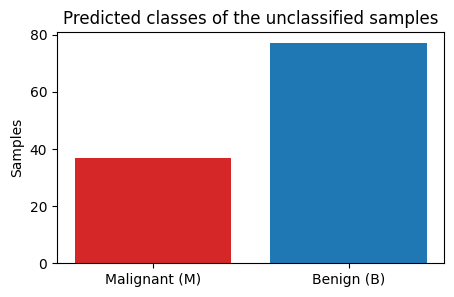

In [4]:
import matplotlib.pyplot as plt

CLASS_NAMES = {"M": "Malignant (M)", "B": "Benign (B)"}

def plot_predicted_classes(predicted):
    """Print how many samples got each class and the first 10 with their confidence; plot the counts."""
    counts = {c: sum(str(r["prediction"]) == c for r in predicted) for c in CLASS_NAMES}
    print(f"\nOf the {len(predicted)} unclassified samples, the model classifies "
          f"{counts['M']} as malignant (M) and {counts['B']} as benign (B).")
    print("\nThe first 10:")
    print(f"  {'Sample':>6}  {'Predicted':<14}  Confidence")
    for i, r in enumerate(predicted[:10], start=1):
        c = str(r["prediction"])
        print(f"  {i:>6}  {CLASS_NAMES[c]:<14}  {r['probabilities'][c]:.0%}")
    plt.figure(figsize=(5, 3))
    plt.bar([CLASS_NAMES[c] for c in counts], list(counts.values()), color=["tab:red", "tab:blue"])
    plt.ylabel("Samples")
    plt.title("Predicted classes of the unclassified samples")
    plt.show()

# Classify the samples and show the results
results = client.inference.run(train_id, unclassified_file, verbose=True)
predicted = results["predictions"]
plot_predicted_classes(predicted)

## 3. Check the predicted classes

The actual diagnoses of these samples are in `data/wdbc_unclassified_actual.csv`, which the model never sees. With your own data there would be no such file.

In [5]:
import csv
with open("data/wdbc_unclassified_actual.csv", newline="") as f:
    actual = [row["diagnosis"] for row in csv.DictReader(f)]

correct = sum(str(r["prediction"]) == a for r, a in zip(predicted, actual))
print(f"{correct} of {len(actual)} classified correctly ({correct / len(actual):.1%})")
for c in CLASS_NAMES:
    right = sum(str(r["prediction"]) == a == c for r, a in zip(predicted, actual))
    print(f"  {CLASS_NAMES[c]}: {right} of {actual.count(c)} classified correctly")

109 of 114 classified correctly (95.6%)
  Malignant (M): 37 of 42 classified correctly
  Benign (B): 72 of 72 classified correctly


## 4. Which features the model relies on

For a random forest, explainable AI gives each column's **importance**: its share of the trees' error reduction. The importances of all 30 columns add up to 1. More in the User Guide: [Random Forest](https://coherent-computing.github.io/redcedar/user_guide/#random-forest).

  [100%] Done.


  worst_perimeter: 17.2%
  worst_area: 13.7%
  worst_radius: 11.0%
  mean_concave_points: 9.5%
  worst_concave_points: 8.5%
  mean_perimeter: 6.2%
  mean_area: 6.1%
  mean_concavity: 5.4%
  mean_radius: 5.0%
  area_error: 4.2%


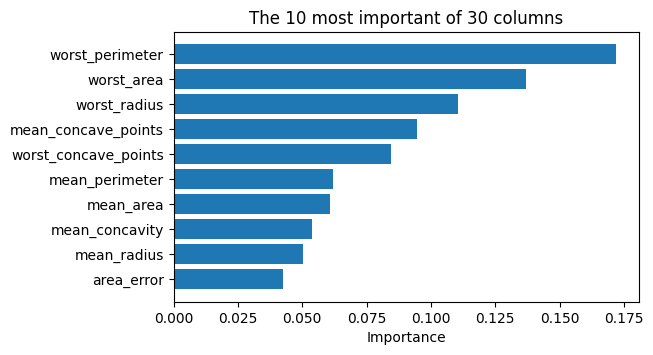

In [6]:
def plot_feature_importance(importances, top=10):
    """Print the most important columns; plot them."""
    importances = importances[:top]   # largest first
    for f in importances:
        print(f"  {f['feature_name']}: {f['importance']:.1%}")
    plt.figure(figsize=(6, 3.5))
    plt.barh([f["feature_name"] for f in importances], [f["importance"] for f in importances])
    plt.gca().invert_yaxis()
    plt.xlabel("Importance")
    plt.title(f"The {top} most important of {len(explanation['feature_importances'])} columns")
    plt.show()

# Explain the model and show the results
explanation = client.explainable.run(train_id, verbose=True)
plot_feature_importance(explanation["feature_importances"])

## Next steps

- `07_quantum_and_forest.ipynb`: the quantum model and the random forest side by side, on the same rows
- `01_quick_start.ipynb`: the same steps with the quantum model